In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [9]:
df = pd.read_csv(r"C:\Users\leolo\Downloads\archive (1)\amz_uk_price_prediction_dataset.csv")

In [10]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [11]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [12]:
df = df[df.columns[df.isnull().mean() < 0.8]]

In [15]:
best_seller = df.groupby("category")["isBestSeller"].mean() * 100


In [16]:
best_seller.head(10)

category
3D Printers                          0.403226
3D Printing & Scanning               0.049176
Abrasive & Finishing Products        2.000000
Action Cameras                       0.058928
Adapters                             1.181102
Agricultural Equipment & Supplies    1.277843
Alexa Built-In Devices               0.934579
Art & Craft Supplies                 1.937984
Arts & Crafts                        2.408629
Baby                                 2.265781
Name: isBestSeller, dtype: float64

In [17]:
from scipy.stats import chi2_contingency

In [18]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [19]:
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

0.1222829439760564

<Axes: xlabel='category'>

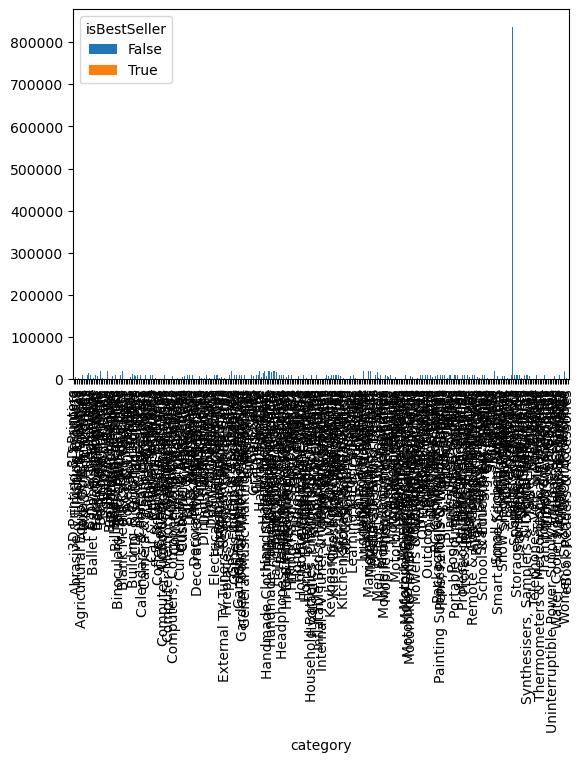

In [20]:
crosstab_result.plot(kind="bar", stacked=True)

In [32]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]

C:\Users\leolo\AppData\Local\Temp\ipykernel_35136\83458352.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20_no_outliers, x='price', y='category', palette="coolwarm")


<Axes: xlabel='price', ylabel='category'>

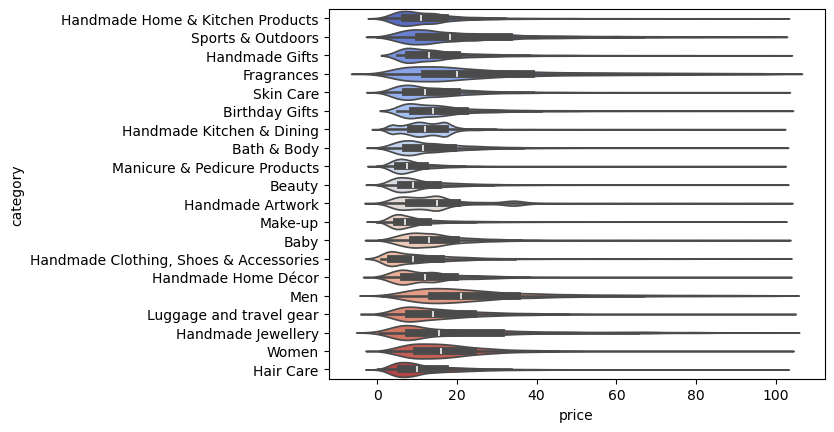

In [35]:
top_20_categories = df_no_outliers["category"].value_counts().head(20).index

df_top20_no_outliers = df_no_outliers[
    df_no_outliers["category"].isin(top_20_categories)
]

sns.violinplot(data=df_top20_no_outliers, x='price', y='category', palette="coolwarm")

C:\Users\leolo\AppData\Local\Temp\ipykernel_35136\144012065.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10_no_outliers, y='category', x='price', palette="coolwarm", errorbar=None)


<Axes: xlabel='price', ylabel='category'>

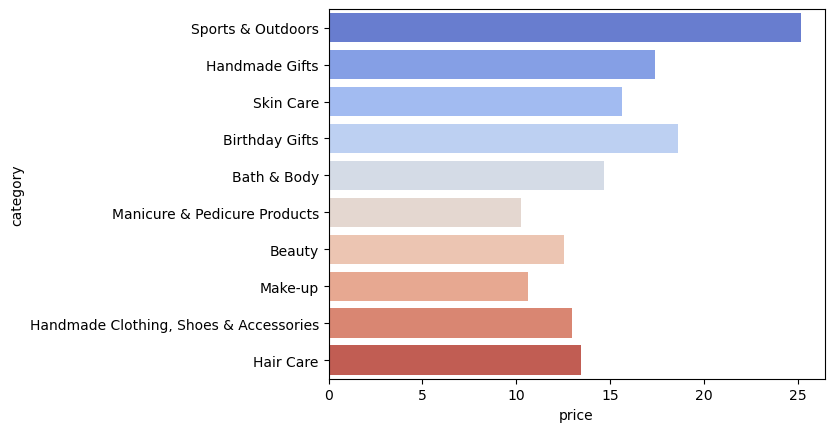

In [38]:
top_10_categories = df_no_outliers["category"].value_counts().head(10).index

df_top10_no_outliers = df_no_outliers[
    df_no_outliers["category"].isin(top_10_categories)
]

sns.barplot(data=df_top10_no_outliers, y='category', x='price', palette="coolwarm", errorbar=None)

In [41]:
avg_price_by_category = df_no_outliers.groupby("category")["price"].mean()
avg_price_by_category

category
3D Printers                       55.739722
3D Printing & Scanning            35.623904
Abrasive & Finishing Products     14.427611
Action Cameras                    38.936875
Adapters                           8.750197
                                    ...    
Wind Instruments                  18.935339
Window Treatments                 19.870633
Women                             20.408735
Women's Sports & Outdoor Shoes    49.425894
eBook Readers & Accessories       26.006952
Name: price, Length: 296, dtype: float64

C:\Users\leolo\AppData\Local\Temp\ipykernel_35136\3239074006.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10_no_outliers, y='stars', x='category', palette="coolwarm")


<Axes: xlabel='category', ylabel='stars'>

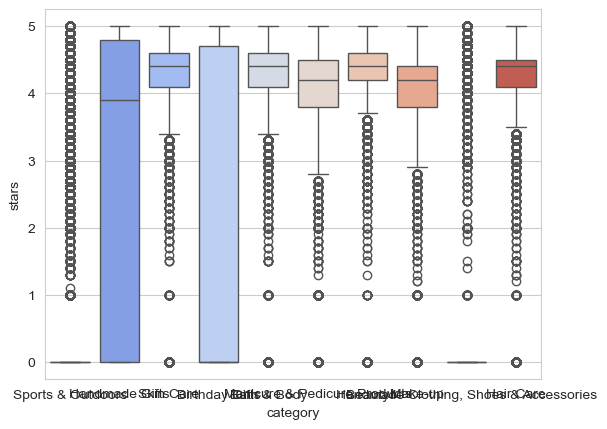

In [48]:
sns.boxplot(data=df_top10_no_outliers, y='stars', x='category', palette="coolwarm")

In [49]:
better_rating = df_no_outliers.groupby("category")["stars"].mean()
better_rating.sort_values(ascending=False)

category
Luxury Food & Drink                       4.544140
Grocery                                   4.469414
Laptop Accessories                        4.449600
Health & Personal Care                    4.439549
Arts & Crafts                             4.432942
                                            ...   
Boxing Shoes                              0.160470
Motorbike Handlebars, Controls & Grips    0.134289
Motorbike Electrical & Batteries          0.105697
3D Printing & Scanning                    0.094067
CD, Disc & Tape Players                   0.048834
Name: stars, Length: 296, dtype: float64

In [50]:
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.12490673262159065)

In [ ]:
## The value of -0.12 indicates a very weak negative correlation.

<Axes: xlabel='price', ylabel='stars'>

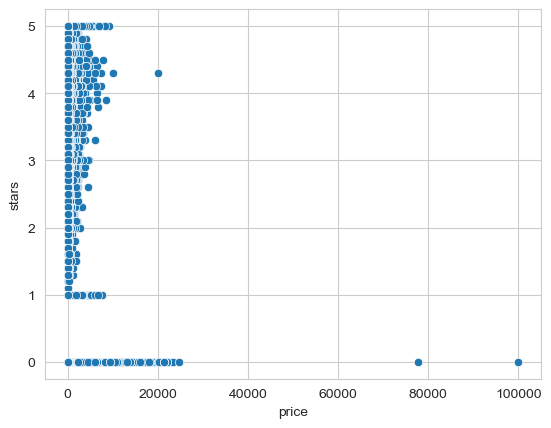

In [52]:
sns.scatterplot(data=df, y='stars', x='price')

In [ ]:
## Price is not a good predictor of whether a product will be well-rated or not.